# Analysis — Many Particles


## Configuração

Edite apenas esta célula para adicionar/remover partículas ou frequências.


In [15]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np

np.seterr("warn")

from treament_tcspc_data import (
    fetch_data_filenames,
    extract_data_info_from_path,
    get_xf_yf_fund,
    get_mean_amp_and_phase,
    time_domain_visual_verification,
    # get_fft,
)
from snr_aux_functions import get_snr_db, plot_time_and_freq_domain

In [16]:
filenames_all = fetch_data_filenames("./raw-data/y2o3-yber-1M-pwd-50mA/square")

In [ ]:
exc_data_npy = np.load("raw-data/y2o3-yber-1M-pwd-50mA/square/amp_5e-1_offset_7e-1/exc_laser40mA_counts40k/offset_4e-1_amp_7e-1_freq_50Hz_nrep_20_time_gate_150_cycles_2.npy",
                       allow_pickle=True)

lum_data_npy = np.load("raw-data/y2o3-yber-1M-pwd-50mA/square/amp_5e-1_offset_7e-1/lum_laser50mA_counts18k/offset_4e-1_amp_7e-1_freq_50Hz_nrep_20_time_gate_150_cycles_2.npy",
                       allow_pickle=True)

In [18]:
SAMPLES_LIST = {
    "Y2O3: Yb/Er 50mA - Square": {
        "lum_path": "raw-data/y2o3-yber-1M-pwd-50mA/square/amp_5e-1_offset_7e-1/lum_laser50mA_counts18k"
    },
    # "Y2O3: Yb/Er 200mA": {
    #     "lum_path": "raw-data/y2o3-yber-1M-pwd-200mA/varying_amp_offset_4e-1/lum_laser200mA_counts35k_OD_15e-2"
    # },
    # "Y2O3: Yb/Er 800mA": {
    #     "lum_path": "raw-data/y2o3-yber-1M-pwd-800mA/lum_laser800mA_counts30k_OD_23e-2"
    # },
}

In [19]:
# Populate particle list
samples_list = [
    {
        "sample_label": sample,
        "sample_data": np.load("raw-data/y2o3-yber-1M-pwd-50mA/square/amp_5e-1_offset_7e-1/lum_laser50mA_counts18k/offset_4e-1_amp_7e-1_freq_50Hz_nrep_20_time_gate_150_cycles_2.npy",
                               allow_pickle=True)
    }
    for sample in SAMPLES_LIST
]

list

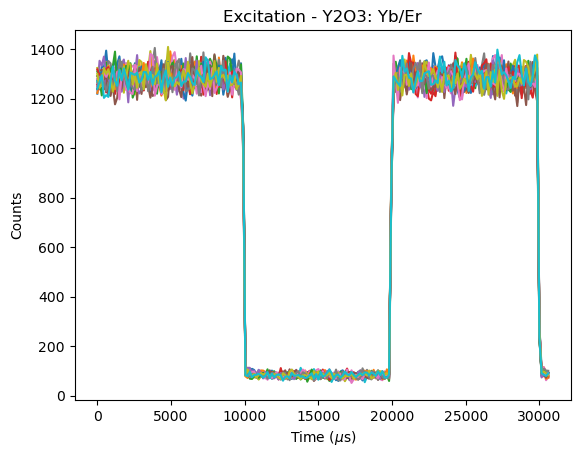

In [ ]:
for meas in range(20):
    plt.plot(exc_data_npy[meas][0], exc_data_npy[meas][1])

plt.title("Excitation - Y2O3: Yb/Er")
plt.ylabel("Counts")
plt.xlabel("Time ($\mu$s)")


plt.show()

In [ ]:
for meas in range(20):
    plt.plot(exc_data_npy[meas][0], exc_data_npy[meas][1])

plt.title("Excitation - Y2O3: Yb/Er")
plt.ylabel("Counts")
plt.xlabel("Time ($\mu$s)")


plt.show()

## Análise — loop sobre N partículas


### Plot all


In [20]:
time_domain_visual_verification(
    samples_list,
    # samples_off=[i for i in range(len(samples_list)) if (i != 0)],
    # show_mean=True,
)


  Processing Y2O3: Yb/Er 50mA - Square  


TypeError: list indices must be integers or slices, not str


  Processing Laser  


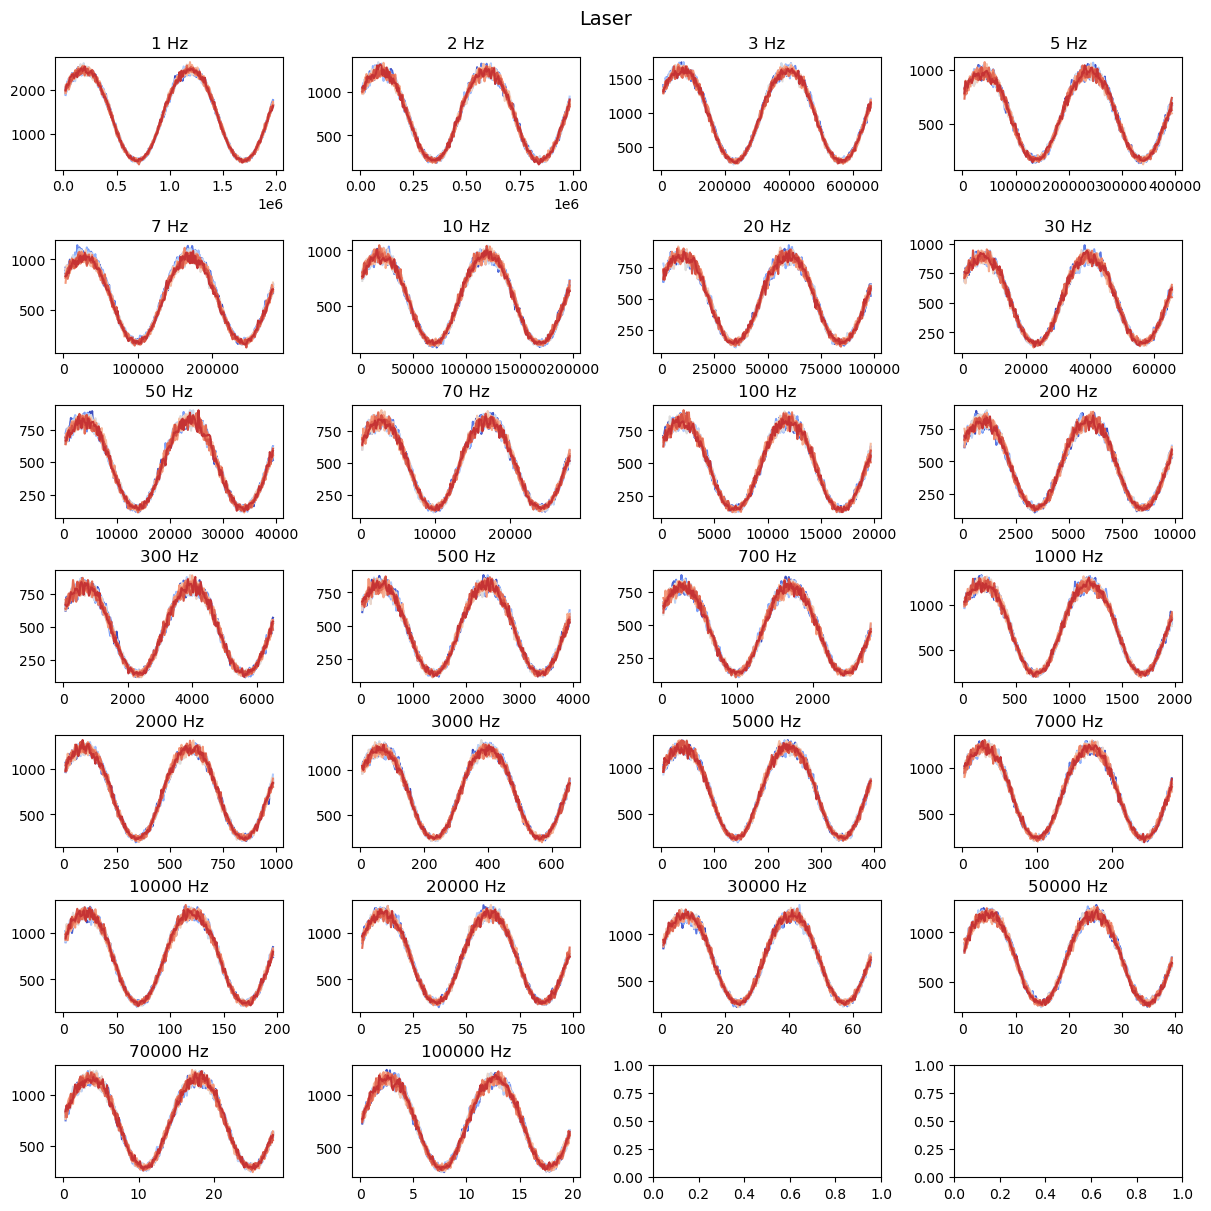

In [7]:
# Excitation
time_domain_visual_verification(
    [
        {
            "sample_label": "Laser",
            "sample_data": exc_data_npy
        }
    ]
)

## Get mean phases and errors


In [8]:
# Calculate list of phasors for the laser and all measurements
for step in exc_data_npy:
    freq = step["freq"]
    step["fft_amp_list"] = []
    for meas_idx, meas in enumerate(step["data"]):
        _, amp = get_xf_yf_fund(meas[:, 0], meas[:, 1], freq)
        step["fft_amp_list"].append(amp)

In [9]:
# Get mean phase and error for each particle and each step (freq)
for step in exc_data_npy:
    freq = step["freq"]
    amp_list = step["fft_amp_list"]
    _, _, phase, phase_error = get_mean_amp_and_phase(amp_list)
    step["mean_fft_info"] = [freq, phase, phase_error]

In [10]:
# Calculate list of phasors for all particles and all measurements
for sample in samples_list:
    for step in sample["sample_data"]:
        freq = step["freq"]
        step["fft_amp_list"] = []
        for meas_idx, meas in enumerate(step["data"]):
            _, amp = get_xf_yf_fund(meas[:, 0], meas[:, 1], freq)
            step["fft_amp_list"].append(amp)

In [11]:
# Get mean phase and error for each particle and each step (freq)
for sample in samples_list:
    for step in sample["sample_data"]:
        freq = step["freq"]
        amp_list = step["fft_amp_list"]
        _, _, phase, phase_error = get_mean_amp_and_phase(amp_list)
        step["mean_fft_info"] = [freq, phase, phase_error]

## Comparison — all particles


In [12]:
def get_error_bar(exc_data, samples_list):
    exc = np.array([step["mean_fft_info"] for step in exc_data])

    for sample in samples_list:
        smp = np.array([step["mean_fft_info"] for step in sample["sample_data"]])

        if smp.shape != exc.shape or not np.allclose(smp[:, 0], exc[:, 0]):
            raise ValueError(
                f"Frequencies do not match for sample {sample.get('sample_label')}"
            )

        pd_raw = smp[:, 1] - exc[:, 1]
        pd_list = np.unwrap(np.angle(np.exp(1j * pd_raw)))
        pd_error = np.hypot(smp[:, 2], exc[:, 2])

        sample["error_bar"] = np.column_stack((smp[:, 0], pd_list, pd_error))


get_error_bar(exc_data_npy, samples_list)

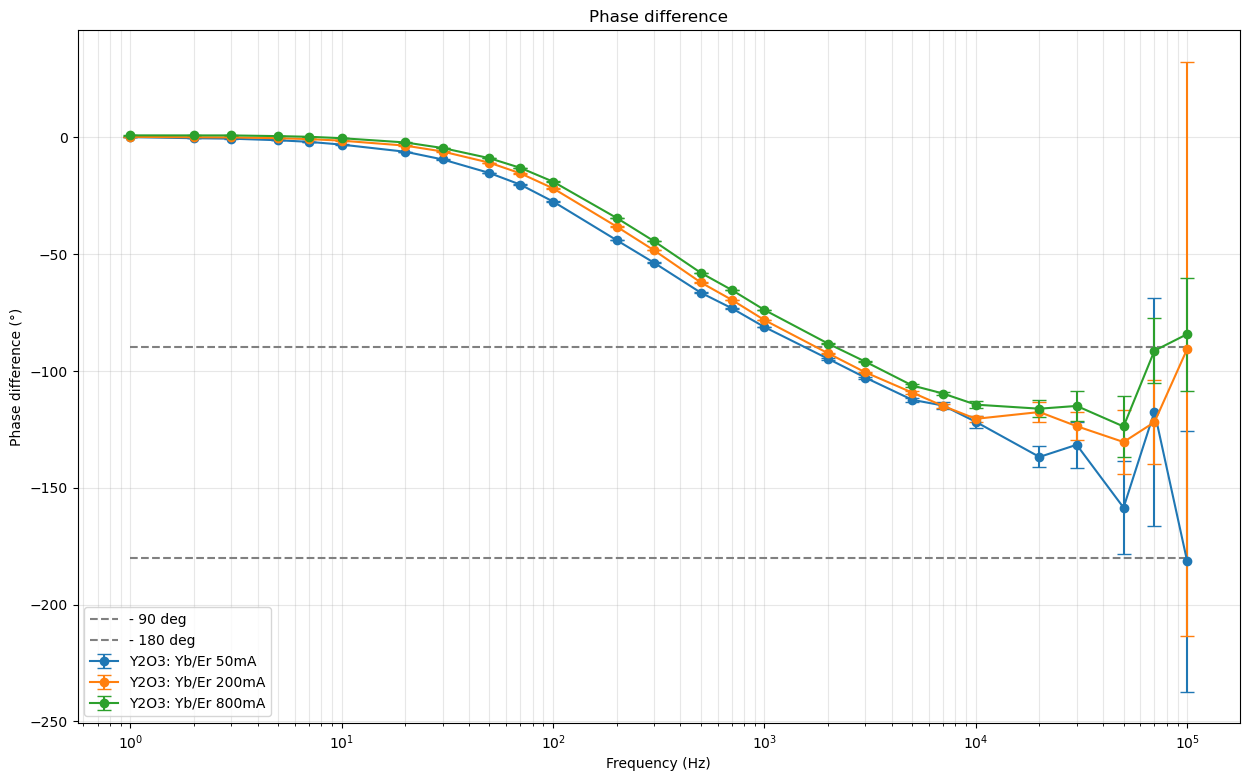

In [13]:
def plot_phase_difference(samples: list, samples_to_skip=[], freqs_to_skip=[]):
    plt.figure(figsize=(15, 9))

    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for sample_id, sample in enumerate(samples):
        if sample_id in samples_to_skip:
            continue
        color = colors[sample_id % len(colors)]

        data = np.asarray(sample["error_bar"])           # colunas: freq, fase, erro
        data = data[~np.isin(data[:, 0], freqs_to_skip)] # remove as frequências puladas
        data = data[np.argsort(data[:, 0])]              # ordena por frequência
        
        if data.size == 0:
            continue
        freqs, phases, errors = data.T

        plt.errorbar(
            freqs,
            np.rad2deg(phases),
            yerr=np.rad2deg(errors),
            label=f"{sample['sample_label']}",
            fmt="o-",
            capsize=5,
            color=color,
        )

    plt.hlines(-90, xmin=freqs[0], xmax=freqs[-1], linestyles="--", colors="gray", label="- 90 deg")
    plt.hlines(-180, xmin=freqs[0], xmax=freqs[-1], linestyles="--", colors="gray", label="- 180 deg")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Phase difference (°)")
    plt.xscale("log")
    plt.title("Phase difference")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.show()

plot_phase_difference(
    samples_list,
    # samples_to_skip=[i for i in range(1, 31) if (i != 1) and (i != 2)],
    # freqs_to_skip = freq_list[-2:],
)

In [14]:
print([samples_list[i]["sample_label"] for i in range(len(samples_list))])

['Y2O3: Yb/Er 50mA', 'Y2O3: Yb/Er 200mA', 'Y2O3: Yb/Er 800mA']


In [ ]:
# np.save(
#     "y2o3_yber_phase_diff",
#     [samples_list[i]["error_bar"] for i in range(len(samples_list))]
# )